In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

# 1. Veri Dönüşümleri (Preprocessing)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # Pikselleri -1 ile 1 arasına ölçekler
])

# 2. MNIST Veri Setini İndirme
full_train_dataset = torchvision.datasets.MNIST(root='./data', 
                                                train=True, 
                                                download=True, 
                                                transform=transform)

test_dataset = torchvision.datasets.MNIST(root='./data', 
                                          train=False, 
                                          download=True, 
                                          transform=transform)

# 3. Train ve Validation Ayrımı (50.000 Eğitim, 10.000 Doğrulama)
train_size = 50000
val_size = 10000
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# 4. DataLoader Oluşturma
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Eğitim (Train) verisi sayısı: {len(train_dataset)}")
print(f"Doğrulama (Validation) verisi sayısı: {len(val_dataset)}")
print(f"Test verisi sayısı: {len(test_dataset)}")

Eğitim (Train) verisi sayısı: 50000
Doğrulama (Validation) verisi sayısı: 10000
Test verisi sayısı: 10000


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class MLPModel(nn.Module):
    def __init__(self):
        super(MLPModel, self).__init__()
        
        # 1. Gizli Katman (128 nöron)
        self.fc1 = nn.Linear(28 * 28, 128)
        
        # 2. Gizli Katman (64 nöron)
        self.fc2 = nn.Linear(128, 64)
        
        # Çıktı katmanı: 0'dan 9'a kadar 10 sınıfımız olduğu için 10 nöron
        self.out = nn.Linear(64, 10)

    def forward(self, x):
        # Görüntüyü düzleştirme (Flatten işlemi)
        x = x.view(-1, 28 * 28)
        
        # Gizli katmanlardan geçerken ReLU aktivasyon fonksiyonu uygulandı
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        
        # Çıktı katmanından çıkan ham sonuçları (logits) döndürüyoruz
        x = self.out(x)
        return x

model = MLPModel()
print(model)

MLPModel(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (out): Linear(in_features=64, out_features=10, bias=True)
)


In [ ]:
import torch.optim as optim
import time
import torch

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001) # Adam fonksiyonu kullanıldı

# Eğitim iterasyonu sayısı
epochs = 10

# Grafik çizimi için değerleri tutacağımız listeler
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], [] 

print("Eğitim başlıyor...\n")
start_time = time.time() 

for epoch in range(epochs):
    # --- EĞİTİM (TRAIN) AŞAMASI ---
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct_train / total_train
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    
    # --- DOĞRULAMA (VALIDATION) AŞAMASI ---
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    val_loss = val_loss / len(val_loader)
    val_acc = 100 * correct_val / total_val
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    
    print(f"Epoch [{epoch+1}/{epochs}] | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

end_time = time.time()
print(f"\nToplam Eğitim Süresi: {(end_time - start_time):.2f} saniye")

Eğitim başlıyor...

Epoch [1/10] | Train Loss: 0.4219, Train Acc: 87.35% | Val Loss: 0.3074, Val Acc: 89.97%
Epoch [2/10] | Train Loss: 0.2075, Train Acc: 93.65% | Val Loss: 0.1986, Val Acc: 93.78%
Epoch [3/10] | Train Loss: 0.1537, Train Acc: 95.30% | Val Loss: 0.1532, Val Acc: 95.24%
Epoch [4/10] | Train Loss: 0.1237, Train Acc: 96.19% | Val Loss: 0.1243, Val Acc: 96.28%
Epoch [5/10] | Train Loss: 0.1045, Train Acc: 96.73% | Val Loss: 0.1119, Val Acc: 96.47%
Epoch [6/10] | Train Loss: 0.0884, Train Acc: 97.26% | Val Loss: 0.1075, Val Acc: 96.53%
Epoch [7/10] | Train Loss: 0.0786, Train Acc: 97.44% | Val Loss: 0.1251, Val Acc: 96.31%
Epoch [8/10] | Train Loss: 0.0726, Train Acc: 97.68% | Val Loss: 0.1316, Val Acc: 95.91%
Epoch [9/10] | Train Loss: 0.0650, Train Acc: 97.86% | Val Loss: 0.1207, Val Acc: 96.40%
Epoch [10/10] | Train Loss: 0.0564, Train Acc: 98.20% | Val Loss: 0.1175, Val Acc: 96.88%

Toplam Eğitim Süresi: 24.89 saniye


Test Verisindeki Başarı (Accuracy): 97.00%



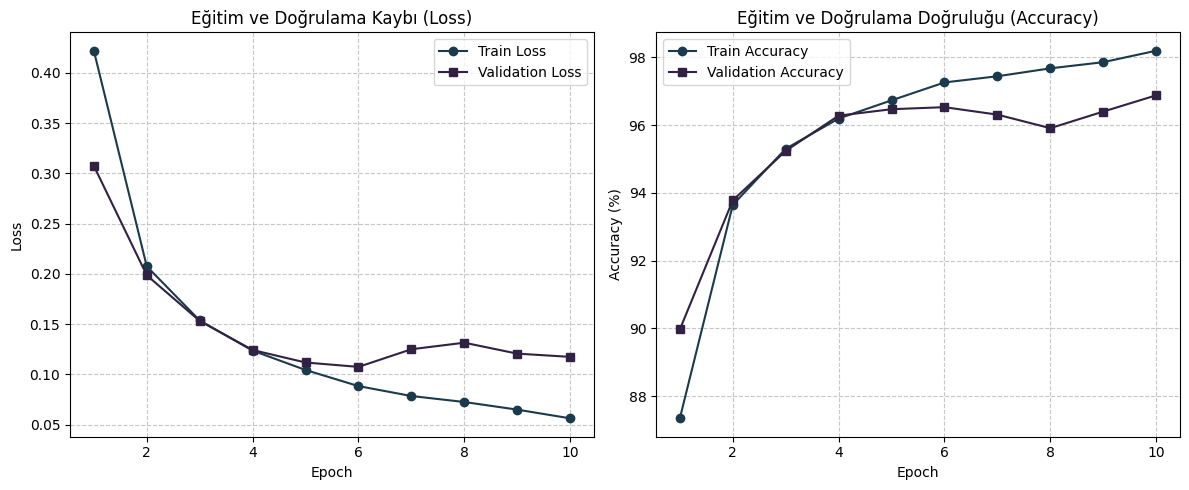

In [ ]:
import matplotlib.pyplot as plt
import torch

# --- 1. TEST SETİ BAŞARISINI ÖLÇME ---
model.eval() 
correct_test = 0
total_test = 0

with torch.no_grad(): 
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test Verisindeki Başarı (Accuracy): {test_acc:.2f}%\n")

# --- 2. EĞİTİM GRAFİKLERİNİ ÇİZDİRME ---
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(12, 5))

# Kayıp (Loss) Grafiği
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss', color='#1B3A4B', marker='o')
plt.plot(epochs_range, val_losses, label='Validation Loss', color='#312244', marker='s')
plt.title('Eğitim ve Doğrulama Kaybı (Loss)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Doğruluk (Accuracy) Grafiği
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accuracies, label='Train Accuracy', color='#1B3A4B', marker='o')
plt.plot(epochs_range, val_accuracies, label='Validation Accuracy', color='#312244', marker='s')
plt.title('Eğitim ve Doğrulama Doğruluğu (Accuracy)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Gerçek Numara:   24120205011
Model Tahminleri: 24120205011

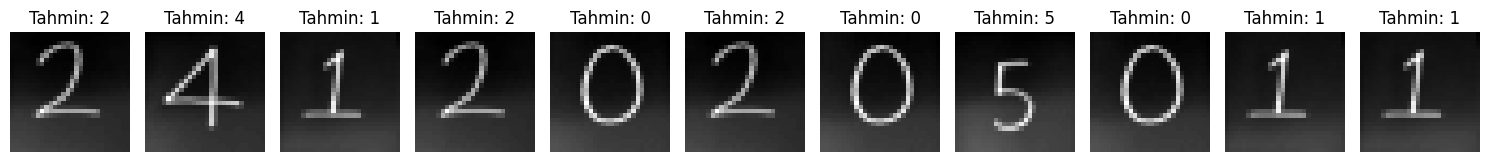

In [14]:
import torch
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import os

# Öğrenci numaram
student_id = "24120205011"

# Ödev Şartları: 28x28 boyut, gri tonlama ve normalizasyon
transform_custom = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), # Resmi tek kanallı gri tona çevirir
    transforms.Resize((28, 28)),                 # Boyutu 28x28 piksele ayarlar
    transforms.ToTensor(),                       # PyTorch tensörüne dönüştürür
    transforms.Lambda(lambda x: 1.0 - x),        # Renkleri ters çevirir (siyah zemin, beyaz yazı)
    transforms.Normalize((0.5,), (0.5,))         # Değerleri -1 ile 1 arasına normalize eder
])

model.eval() 
fig, axes = plt.subplots(1, len(student_id), figsize=(15, 3))

print(f"Gerçek Numara:   {student_id}")
print("Model Tahminleri: ", end="")

for i, digit in enumerate(student_id):
    img_path = f"el_yazim/{digit}.jpg" # Görsel formatları jpg olarak yüklendi
    
    # Görüntü dosyası kontrolü - format farklı ise de görsel yok yazdı 
    if not os.path.exists(img_path):
        print("X", end="")
        axes[i].set_title("Görsel Yok")
        axes[i].axis('off')
        continue
        
    img = Image.open(img_path)
    
    img_tensor = transform_custom(img).unsqueeze(0)
    
    with torch.no_grad():
        output = model(img_tensor)
        _, predicted = torch.max(output.data, 1)
        pred_val = predicted.item()
        
    print(str(pred_val), end="")
    
    # Ekrana çizdirme için gerekli fonksiyonlar
    axes[i].imshow(img_tensor.squeeze(), cmap='gray')
    axes[i].set_title(f"Tahmin: {pred_val}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()